In [4]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

In [5]:
def true_W(r):
    return (
        -2.0 * np.exp(-r**2) / np.sqrt(np.pi)
        -2.0 * np.exp(-0.5 * r**2) / np.sqrt(2.0 * np.pi)
    )

def true_W_prime(r):
    return (
        4.0 * r * np.exp(-r**2) / np.sqrt(np.pi)
        + 2.0 * r * np.exp(-0.5 * r**2) / np.sqrt(2.0 * np.pi)
    )

def dK(r, s, ell):
    return -(r - s) / ell**2 * K(r, s, ell)

def delta_t_plus(rho, dt):
    out = np.zeros_like(rho)
    out[:-1] = (rho[1:] - rho[:-1]) / dt
    out[-1] = -rho[-1] / dt
    return out

def delta_x_plus(u, dx):
    out = np.zeros_like(u)
    out[:-1] = (u[1:] - u[:-1]) / dx
    out[-1] = -u[-1] / dx
    return out

def dx_forward(u, dx):
    out = np.zeros_like(u)
    out[:-1] = (u[1:] - u[:-1]) / dx
    out[-1] = -u[-1] / dx
    return out

def dxx_forward(u, dx):
    ux = dx_forward(u, dx)
    return dx_forward(ux, dx)

def K(r, s, ell):
    return np.exp(-(r - s) ** 2 / (2.0 * ell**2))

# Main inverse solver: A^delta W = f^delta
def recover_W_by_Adelta(rho, x, t, kappa, m, params):
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    num_centers = params["num_centers"]
    ell = params["ell"]
    lam = params["lam"]
    r_max_fit = params["r_max_fit"]
    r_max_plot = params.get("r_max_plot", r_max_fit)
    rho_cut = params["rho_cut"]
    num_plot_points = params["num_plot_points"]
    Ltime, N = rho.shape
    R = x[:, None] - x[None, :]
    centers = np.linspace(0.0, r_max_fit, num_centers)
    J = len(centers)
    rho_t = delta_t_plus(rho, dt)
    rows = []
    vals = []
    weights = []
    for l in range(Ltime - 1):
        rho_l = rho[l]
        rho_x = delta_x_plus(rho_l, dx)
        Uprime = kappa * rho_l ** (m - 1)
        Uprime_x = dx_forward(Uprime, dx)
        Uprime_xx = dxx_forward(Uprime, dx)
        f_l = rho_t[l] - rho_x * Uprime_x - rho_l * Uprime_xx
        mask = rho_l > rho_cut
        mask[:2] = False
        mask[-2:] = False
        M_l = np.zeros((np.sum(mask), J))
        for j, s in enumerate(centers):
            basis = K(R, s, ell) + K(R, -s, ell)
            conv = dx * (basis @ rho_l)
            conv_x = dx_forward(conv, dx)
            conv_xx = dxx_forward(conv, dx)
            A_col = rho_x * conv_x + rho_l * conv_xx
            M_l[:, j] = A_col[mask]
        rows.append(M_l)
        vals.append(f_l[mask])
        weights.append(rho_l[mask])
    Mmat = np.vstack(rows)
    y = np.concatenate(vals)
    w = np.concatenate(weights)
    sw = np.sqrt(w)
    Mw = Mmat * sw[:, None]
    yw = y * sw
    S = Mw.T @ Mw
    b = Mw.T @ yw
    scale = np.trace(S) / J
    A = S + lam * scale * np.eye(J)
    print("training samples =", Mmat.shape[0])
    print("unknowns =", J)
    print("lambda =", lam)
    print("effective lambda =", lam * scale)
    print("cond(A) =", np.linalg.cond(A))
    cf = cho_factor(A + 1e-12 * np.eye(J), lower=True)
    alpha = cho_solve(cf, b)
    r_plot = np.linspace(-r_max_plot, r_max_plot, num_plot_points)
    W_hat = np.zeros_like(r_plot)
    Wp_hat = np.zeros_like(r_plot)
    for aj, s in zip(alpha, centers):
        W_hat += aj * (K(r_plot, s, ell) + K(r_plot, -s, ell))
        Wp_hat += aj * (dK(r_plot, s, ell) + dK(r_plot, -s, ell))
    return {
        "r_plot": r_plot,
        "W_hat": W_hat,
        "Wp_hat": Wp_hat,   
        "alpha": alpha,
        "centers": centers,
        "M_shape": Mmat.shape,
        "cond_A": np.linalg.cond(A),
    }

def relative_L2_error(f_hat, f_true, mask):
    return (
        np.linalg.norm(f_hat[mask] - f_true[mask])
        /
        np.linalg.norm(f_true[mask])
    )


Dataset = example2_sparse_Cx5_Ct250
rho shape = (61, 192)
dx = 0.0625
dt = 0.025
m = 3
kappa = 0.48
Cx = 5
Ct = 250
Delta_x = 0.0625
Delta_t = 0.025
training samples = 6699
unknowns = 60
lambda = 0.0001
effective lambda = 0.0029213386410142975
cond(A) = 372565.72206615616
[-2,2] : W = 8.9534e-03, W' = 4.0650e-02
[-4,4] : W = 9.0891e-02, W' = 1.8382e-01
[-6,6] : W = 1.5739e-01, W' = 1.8625e-01


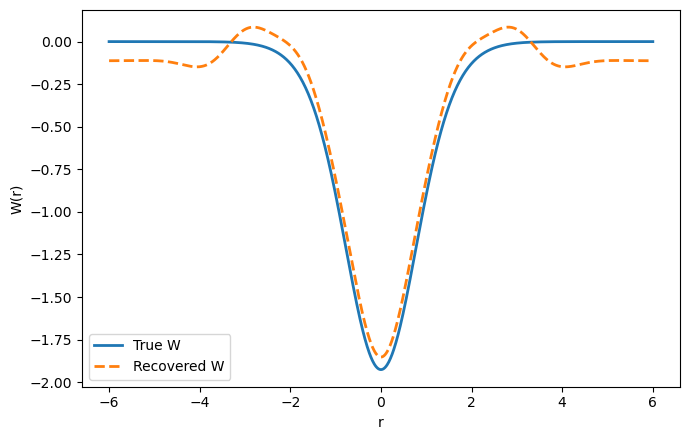

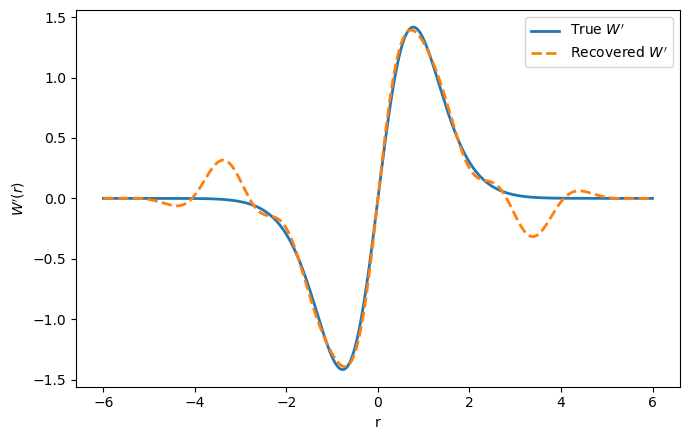

In [24]:
# Example 2: Adelta inversion with kernel method
# Test 1: sparse data 

# Parameters
# params = {
#     "data_file": "example2_sparse_Cx5_Ct250.npz",
#     "num_centers": 60,
#     "ell": 0.60,
#     "lam": 1e-4,
#     "r_max_fit": 4.0,
#     "r_max_plot": 6.0,
#     "rho_cut": 1e-4,
#     "num_plot_points": 1000,
# }
params = {
    "data_file": "example2_sparse_Cx5_Ct250.npz",
    "num_centers": 60,
    "ell": 0.60,
    "lam": 1e-4,
    "r_max_fit": 4.0,
    "r_max_plot": 6.0,
    "rho_cut": 1e-6,
    "num_plot_points": 1000,
}

data = np.load(params["data_file"])
tag = os.path.splitext(os.path.basename(params["data_file"]))[0]
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
print("Dataset =", tag)
print("rho shape =", rho.shape)
print("dx =", x[1] - x[0])
print("dt =", t[1] - t[0])
print("m =", m)
print("kappa =", kappa)

if "Cx" in data:
    print("Cx =", int(data["Cx"]))
if "Ct" in data:
    print("Ct =", int(data["Ct"]))
if "Delta_x" in data:
    print("Delta_x =", float(data["Delta_x"]))
if "Delta_t" in data:
    print("Delta_t =", float(data["Delta_t"]))


# Run estimator
result = recover_W_by_Adelta(rho, x, t, kappa, m, params)
r_plot = result["r_plot"]
W_hat_raw = result["W_hat"]
Wp_hat = result["Wp_hat"]
W_ref = true_W(r_plot)
Wp_ref = true_W_prime(r_plot)
for R in [2, 4, 6]:
    mask = np.abs(r_plot) <= R
    W_hat = W_hat_raw + np.mean(W_ref[mask] - W_hat_raw[mask])
    print(
        f"[-{R},{R}] : "
        f"W = {relative_L2_error(W_hat, W_ref, mask):.4e}, "
        f"W' = {relative_L2_error(Wp_hat, Wp_ref, mask):.4e}"
    )
W_hat = W_hat_raw + np.mean(W_ref - W_hat_raw)

# save figures
os.makedirs("figures_kernel_Adelta", exist_ok=True)
plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, W_ref, label="True W", linewidth=2)
plt.plot(r_plot, W_hat, "--", label="Recovered W", linewidth=2)
plt.xlabel("r")
plt.ylabel("W(r)")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_W.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_W.pdf", bbox_inches="tight",)
plt.show()


plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, Wp_ref, label="True $W'$", linewidth=2)
plt.plot(r_plot, Wp_hat, "--", label="Recovered $W'$", linewidth=2)
plt.xlabel("r")
plt.ylabel(r"$W'(r)$")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_Wprime.png", dpi=300, bbox_inches="tight",)
plt.savefig( f"figures_kernel_Adelta/{tag}_Adelta_recovered_Wprime.pdf", bbox_inches="tight",)
plt.show()

Dataset = example2_sparse_Cx2_Ct50
rho shape = (301, 480)
dx = 0.025000000000000355
dt = 0.005
m = 3
kappa = 0.48
Cx = 2
Ct = 50
Delta_x = 0.025
Delta_t = 0.005
training samples = 77025
unknowns = 120
lambda = 0.0001
effective lambda = 0.036822607743957333
cond(A) = 749087.4080153831
[-2,2] : W = 2.3237e-03, W' = 9.1709e-03
[-4,4] : W = 1.8767e-02, W' = 4.9657e-02
[-6,6] : W = 1.2763e-01, W' = 1.0927e-01


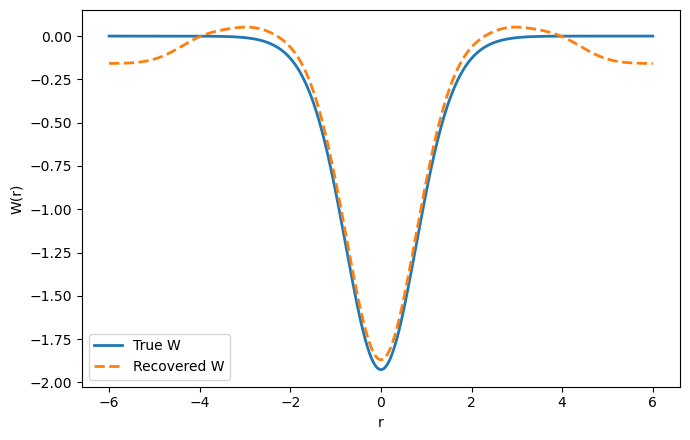

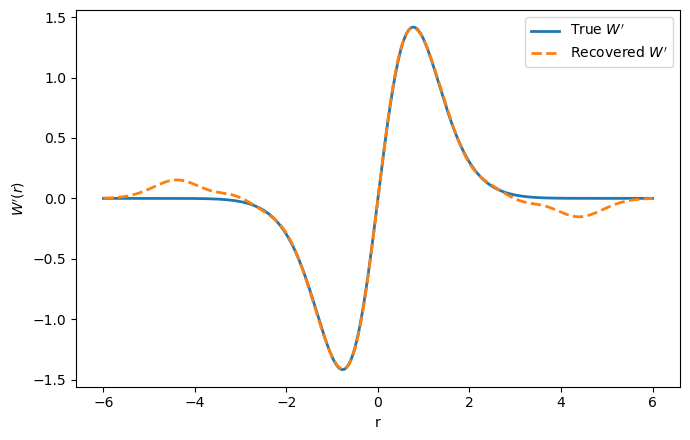

In [ ]:
# Example 2: Adelta inversion with kernel method
# Test 2: fine data 

# Parameters
params = {
    "data_file": "example2_sparse_Cx2_Ct50.npz",
    "num_centers": 120,
    "ell": 0.60,
    "lam": 1e-4,
    "r_max_fit": 6.0,
    "r_max_plot": 6.0,
    "rho_cut": 1e-5,
    "num_plot_points": 1000,
}

data = np.load(params["data_file"])
tag = os.path.splitext(os.path.basename(params["data_file"]))[0]
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
print("Dataset =", tag)
print("rho shape =", rho.shape)
print("dx =", x[1] - x[0])
print("dt =", t[1] - t[0])
print("m =", m)
print("kappa =", kappa)

if "Cx" in data:
    print("Cx =", int(data["Cx"]))
if "Ct" in data:
    print("Ct =", int(data["Ct"]))
if "Delta_x" in data:
    print("Delta_x =", float(data["Delta_x"]))
if "Delta_t" in data:
    print("Delta_t =", float(data["Delta_t"]))


# Run estimator
result = recover_W_by_Adelta(rho, x, t, kappa, m, params)
r_plot = result["r_plot"]
W_hat_raw = result["W_hat"]
Wp_hat = result["Wp_hat"]
W_ref = true_W(r_plot)
Wp_ref = true_W_prime(r_plot)
for R in [2, 4, 6]:
    mask = np.abs(r_plot) <= R
    W_hat = W_hat_raw + np.mean(W_ref[mask] - W_hat_raw[mask])
    print(
        f"[-{R},{R}] : "
        f"W = {relative_L2_error(W_hat, W_ref, mask):.4e}, "
        f"W' = {relative_L2_error(Wp_hat, Wp_ref, mask):.4e}"
    )
W_hat = W_hat_raw + np.mean(W_ref - W_hat_raw)

# save figures
os.makedirs("figures_kernel_Adelta", exist_ok=True)
plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, W_ref, label="True W", linewidth=2)
plt.plot(r_plot, W_hat, "--", label="Recovered W", linewidth=2)
plt.xlabel("r")
plt.ylabel("W(r)")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_W.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_W.pdf", bbox_inches="tight",)
plt.show()


plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, Wp_ref, label="True $W'$", linewidth=2)
plt.plot(r_plot, Wp_hat, "--", label="Recovered $W'$", linewidth=2)
plt.xlabel("r")
plt.ylabel(r"$W'(r)$")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_Adelta/{tag}_Adelta_recovered_Wprime.png", dpi=300, bbox_inches="tight",)
plt.savefig( f"figures_kernel_Adelta/{tag}_Adelta_recovered_Wprime.pdf", bbox_inches="tight",)
plt.show()